# TP 1 – An experimental protocol for supervised learning – Solutions

This first practical session sets up the experimental protocol that we will use in all the following ones. On two simple families of models, Gaussian kernel SVMs and decision trees, we distinguish the empirical risk from the true risk, we see why and when the data must be normalized, we search hyperparameters with a validation set and with cross-validation, and we evaluate the final model once, on a test set kept aside. The last two parts open the programme of the course: combining many trees into a vote (ensemble methods, TP 2 and 3), and turning a test error into a *guarantee* on the true risk (generalization bounds and PAC-Bayes, TP 4 and 5). The session lasts **three hours**; Part 7 contains the difficult questions and can be left for home. All the numbers and figures of these solutions are produced by the code of this notebook (one function per part, about two minutes in total); with other random seeds your numbers will differ slightly.

*Statistical Supervised Machine Learning – Master MIASHS & MALIA. Run the cells in order, from the folder of this notebook (it uses `../common` and `../data`). Each part: the statement, the code, then the solutions with the tables and figures produced by the code.*

**Data.** A synthetic problem whose distribution is known (Part 1), and three datasets of the course loaded with `load(name)` of `common/tptools.py`, with labels in $\{-1,+1\}$: `wdbc` (breast cancer, $569\times30$), `pima` (diabetes, $768\times8$) and `australian` (credit, $690\times14$). The file `tp1_starter.py` contains the data generator and the imports.

> **Good practice.** Fix all the random seeds (`random_state=seed`). Never call `fit` on data that contains test examples, and put every preprocessing step in a `Pipeline` so that cross-validation refits it on each training fold. Keep the test set in a variable that you use only once, at the end.

## Setup

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
sys.path.insert(0, os.path.join(HERE, "..", "common"))
from tptools import load, kl_inv_upper, hoeffding_width, show_table as _show_rows

DELTA = 0.05
C1, C2, C3, C4, C5, GREY = "#1f5f99", "#c8553d", "#2a9d8f", "#e9a13b", "#6c4f9c", "#8c8c8c"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.bbox": "tight"})


plt.rcParams["figure.dpi"] = 120

# column headers of the tables
HEADERS = {
    'p1_bayes': ['$R^\\star$', 'error of $c$ on $50\\,000$ examples'],
    'p1_risks': ['model', 'empirical risk', 'true risk'],
    'p1_fresh': ['$n$', '$R_{\\mathcal{D}}(h)$', 'mean of $\\widehat R_n(h)$', 'std of $\\widehat R_n(h)$', '$\\sqrt{R_{\\mathcal{D}}(h)(1-R_{\\mathcal{D}}(h))/n}$'],
    'p2_scaling': ['data', 'feature std', 'Gaussian SVM – raw', 'Gaussian SVM – standardized', 'tree of depth 4 – raw', 'tree of depth 4 – standardized'],
    'p3_selected': ['model', 'selected hyperparameters', 'CV error', 'test error'],
    'p3_holdout_cv': ['procedure', 'distinct pairs selected', 'selected validation error', 'test error of the selected model'],
    'p4_protocol': ['data', 'SVM ($25$ pairs) – best CV error', 'SVM ($25$ pairs) – test error', 'tree ($28$ pairs) – best CV error', 'tree ($28$ pairs) – test error'],
    'p4_random': ['number of pairs', 'best CV error', 'test error'],
    'p5_vote': ['data', 'one full tree', 'mean error of the $100$ trees', 'vote of the $100$ trees'],
    'p6_bounds': ['data', '$n$', 'test error', 'Hoeffding bound', 'kl bound'],
    'p6_coverage': ['$n$', '$R_{\\mathcal{D}}(h)$', 'mean Hoeffding', 'coverage', 'mean kl bound', 'coverage'],
    'p6_selection': ['$K$', 'selected error', 'coverage with $\\delta$', 'coverage with $\\delta/K$'],
    'p7_leakage': ['(a) selection on all the data', '(b) selection inside each fold'],
}


TABLES, FIGURES = {}, {}


def keep_table(name, rows):
    """Keep the rows of a table ('a & b & c', math between $) to show it later with show_table(name)."""
    TABLES[name] = rows


def keep_figure(fig, name):
    """Keep a figure to show it later with show_figure(name)."""
    FIGURES[name] = fig
    plt.close(fig)


def show_table(name):
    _show_rows(TABLES[name], HEADERS.get(name))


def show_figure(name):
    from IPython.display import display
    display(FIGURES[name])


def err(model, X, y):
    return float(np.mean(model.predict(X) != y))

### The synthetic problem (known distribution, known Bayes risk)

In [2]:
ETA = 0.1


def clean_label(X):
    """+1 above the curve x2 = 0.5 sin(pi x1), -1 below."""
    return np.where(X[:, 1] > 0.5 * np.sin(np.pi * X[:, 0]), 1, -1)


def toy_data(m, rng):
    """X uniform on [-1,1]^2, Y = clean label flipped with probability ETA (Bayes risk = ETA)."""
    X = rng.uniform(-1, 1, size=(m, 2))
    return X, clean_label(X) * np.where(rng.rand(m) < ETA, -1, 1)

## Part 1 – Empirical risk and true risk (Sections 5 and 6.1)

The input $X$ is uniform on $[-1,1]^2$, the clean label is $c(x)=+1$ if $x_2>\frac12\sin(\pi x_1)$ and $-1$ otherwise, and the observed label $Y$ is $c(X)$ flipped with probability $\eta=0.1$. For a classifier $h$, the true risk is $R_{\mathcal{D}}(h)=\mathbb{P}(h(X)\neq Y)$ and the empirical risk on a sample $S=\{(x_i,y_i)\}_{i=1}^m$ is $\widehat{R}_{S}(h)=\frac1m\sum_{i=1}^m\mathbb{1}\left[h(x_i)\neq y_i\right]$.

1.  What is the Bayes classifier of this problem and its risk $R^\star$?\
    Check it on $50\,000$ examples.

2.  Draw a training sample of size $m=200$ and a sample of $50\,000$ examples used as a proxy for the true risk.\
    Plot the empirical (training) risk and the true risk of a decision tree as functions of its maximal depth ($1$ to $15$), and of a Gaussian kernel SVM ($C=10$) as functions of $\gamma\in[10^{-2},10^{3}]$, where the kernel is $k(x,x')=e^{-\gamma\|x-x'\|^2}$.\
    Identify underfitting and overfitting.\
    Plot the decision boundaries of the SVM for $\gamma\in\{0.01,3,100\}$.

3.  Fix the tree of depth $5$.\
    Draw $500$ fresh samples of size $n\in\{50,200,1000,5000\}$, compute its empirical risk on each, and compare their mean and standard deviation with $R_{\mathcal{D}}(h)$ and $\sqrt{R_{\mathcal{D}}(h)(1-R_{\mathcal{D}}(h))/n}$.\
    Why is the empirical risk an unbiased estimate of the true risk here, but not in question 2?

In [3]:
def part1():
    print("Part 1")
    rng = np.random.RandomState(0)
    Xbig, ybig = toy_data(50000, rng)                          # proxy for the true risk
    Xtr, ytr = toy_data(200, rng)
    depths = list(range(1, 16)); gammas = np.logspace(-2, 3, 16)
    tr_t, te_t, tr_s, te_s = [], [], [], []
    for d in depths:
        t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr)
        tr_t.append(err(t, Xtr, ytr)); te_t.append(err(t, Xbig, ybig))
    for g in gammas:
        s = SVC(C=10, gamma=g).fit(Xtr, ytr)
        tr_s.append(err(s, Xtr, ytr)); te_s.append(err(s, Xbig, ybig))
    rows = [f"tree, depth {depths[i]} & {tr_t[i]:.3f} & {te_t[i]:.3f}" for i in [0, 2, 4, 7, 14]]
    rows.append("---")
    rows += [f"SVM, $\\gamma={gammas[i]:.3g}$ & {tr_s[i]:.3f} & {te_s[i]:.3f}" for i in [0, 4, 7, 10, 15]]
    keep_table("p1_risks", rows)
    keep_table("p1_bayes", [f"{ETA:.3f} & {np.mean(clean_label(Xbig) != ybig):.4f}"])
    # variability of the training error of a fixed model, and of the hold-out estimate
    fig, axes = plt.subplots(1, 3, figsize=(7.8, 2.4))
    ax = axes[0]
    ax.plot(depths, tr_t, "o-", ms=3, color=C1, label="empirical risk (training)")
    ax.plot(depths, te_t, "o-", ms=3, color=C2, label="true risk"); ax.axhline(ETA, color="k", ls=":", lw=1, label="Bayes risk")
    ax.set_xlabel("maximal depth"); ax.set_ylabel("error"); ax.set_title("decision tree, $m=200$", fontsize=9); ax.legend(fontsize=7)
    ax = axes[1]
    ax.plot(gammas, tr_s, "o-", ms=3, color=C1); ax.plot(gammas, te_s, "o-", ms=3, color=C2); ax.axhline(ETA, color="k", ls=":", lw=1)
    ax.set_xscale("log"); ax.set_xlabel(r"kernel parameter $\gamma$ ($C=10$)"); ax.set_title("Gaussian kernel SVM, $m=200$", fontsize=9)
    # decision regions of three SVMs
    ax = axes[2]
    xx, yy = np.meshgrid(np.linspace(-1, 1, 300), np.linspace(-1, 1, 300)); G = np.c_[xx.ravel(), yy.ravel()]
    for g, c in [(0.01, C4), (3.0, C3), (100.0, C5)]:
        s = SVC(C=10, gamma=g).fit(Xtr, ytr)
        ax.contour(xx, yy, s.decision_function(G).reshape(xx.shape), levels=[0], colors=[c], linewidths=1.1)
        ax.plot([], [], color=c, label=fr"$\gamma={g:g}$")
    xs = np.linspace(-1, 1, 200); ax.plot(xs, 0.5 * np.sin(np.pi * xs), "k:", lw=1, label="Bayes")
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=np.where(ytr > 0, "#9db8d2", "#e3aa9c"), s=4, zorder=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title("SVM decision boundaries", fontsize=9)
    ax.legend(fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, handlelength=1.2, columnspacing=0.8)
    fig.tight_layout(); keep_figure(fig, "tp1_risks")
    # how far is the empirical risk of a FIXED model on fresh samples of size n from its true risk?
    t = DecisionTreeClassifier(max_depth=5, random_state=0).fit(Xtr, ytr); R = err(t, Xbig, ybig); rows = []
    for n in [50, 200, 1000, 5000]:
        e = np.array([err(t, *toy_data(n, rng)) for _ in range(500)])
        rows.append(f"{n} & {R:.3f} & {e.mean():.3f} & {e.std():.3f} & {np.sqrt(R * (1 - R) / n):.3f}")
    keep_table("p1_fresh", rows)

In [4]:
part1()

Part 1


### Solution

**1.** For every $x$, $\mathbb{P}(Y=c(x)\mid X=x)=0.9>\frac12$: the Bayes classifier predicts the clean label, $h^\star=c$, and $R^\star=\eta=0.1$. Measured on $50\,000$ examples:

In [5]:
show_table("p1_bayes")

| $R^\star$ | error of $c$ on $50\,000$ examples |
|:---:|:---:|
| 0.100 | 0.1004 |

**2.**

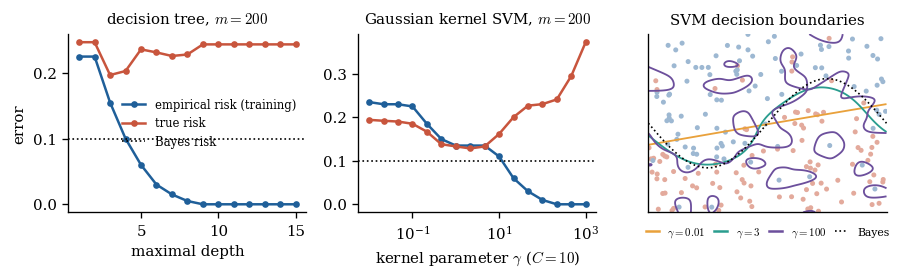

In [6]:
show_figure("tp1_risks")

In [7]:
show_table("p1_risks")

| model | empirical risk | true risk |
|:---:|:---:|:---:|
| tree, depth 1 | 0.225 | 0.247 |
| tree, depth 3 | 0.155 | 0.197 |
| tree, depth 5 | 0.060 | 0.236 |
| tree, depth 8 | 0.005 | 0.228 |
| tree, depth 15 | 0.000 | 0.244 |
| SVM, $\gamma=0.01$ | 0.235 | 0.194 |
| SVM, $\gamma=0.215$ | 0.185 | 0.167 |
| SVM, $\gamma=2.15$ | 0.135 | 0.128 |
| SVM, $\gamma=21.5$ | 0.060 | 0.200 |
| SVM, $\gamma=1e+03$ | 0.000 | 0.373 |

Both families have a parameter that controls the complexity: the depth of the tree, and $\gamma$ for the SVM (a large $\gamma$ means a narrow kernel, i.e. a very flexible boundary). In both cases the empirical risk decreases to $0$ when the complexity increases, while the true risk first decreases and then increases. With few parameters (depth $1$, $\gamma=0.01$) the model is too simple to follow the sine boundary: both risks are high (*underfitting*). With many (depth $\geq8$, $\gamma\geq20$) the model fits the noise of the $200$ examples: the empirical risk is close to $0$ but the true risk is far above $R^\star$ (*overfitting*; for $\gamma=100$ the boundary surrounds individual points). The best SVM ($\gamma\approx2$) has a true risk of $0.128$, close to $R^\star=0.1$; the best tree (depth $3$) only $0.197$, because axis-parallel cuts approximate a smooth curve poorly with $200$ points. The empirical risk of a trained model is a *biased*, optimistic estimate of its true risk, and cannot be used to choose the complexity.

**3.** The tree is now fixed, and the fresh samples are independent of it:

In [8]:
show_table("p1_fresh")

| $n$ | $R_{\mathcal{D}}(h)$ | mean of $\widehat R_n(h)$ | std of $\widehat R_n(h)$ | $\sqrt{R_{\mathcal{D}}(h)(1-R_{\mathcal{D}}(h))/n}$ |
|:---:|:---:|:---:|:---:|:---:|
| 50 | 0.236 | 0.240 | 0.065 | 0.060 |
| 200 | 0.236 | 0.239 | 0.031 | 0.030 |
| 1000 | 0.236 | 0.237 | 0.013 | 0.013 |
| 5000 | 0.236 | 0.239 | 0.006 | 0.006 |

For a classifier $h$ that does not depend on the sample, the $\mathbb{1}\left[h(x_i)\neq y_i\right]$ are i.i.d. Bernoulli variables of mean $R_{\mathcal{D}}(h)$: their average is unbiased, with variance $R_{\mathcal{D}}(h)(1-R_{\mathcal{D}}(h))/n$, which the simulation confirms. In question 2, the same sample is used to *learn* $h$ and to evaluate it; the learner chooses $h$ precisely because it fits this sample, so $\mathbb{E}[\widehat{R}_{S}(h_S)]<\mathbb{E}[R_{\mathcal{D}}(h_S)]$. This is the reason for keeping data that the learner never sees.

## Part 2 – Normalization of the data (Section 11.3)

1.  Look at the standard deviations of the features of `wdbc` and `australian`.\
    What do you notice?

2.  For $10$ random splits ($70\%/30\%$), compute the test error of an SVM (`C=1`, `gamma="scale"`) and of a tree of depth $4$, with and without standardization (`StandardScaler` fitted on the training set).\
    Explain the results.

3.  Why must the scaler be fitted on the training set only?\
    How do you do it inside a cross-validation?

In [9]:
def part2():
    print("Part 2")
    rows = []
    for name in ["wdbc", "australian"]:
        X, y = load(name); R = []
        for seed in range(10):
            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
            sc = StandardScaler().fit(Xtr)
            svm_raw = SVC(C=1, gamma="scale").fit(Xtr, ytr)
            svm_std = SVC(C=1, gamma="scale").fit(sc.transform(Xtr), ytr)
            tree_raw = DecisionTreeClassifier(max_depth=4, random_state=0).fit(Xtr, ytr)
            tree_std = DecisionTreeClassifier(max_depth=4, random_state=0).fit(sc.transform(Xtr), ytr)
            R.append((err(svm_raw, Xte, yte), err(svm_std, sc.transform(Xte), yte),
                      err(tree_raw, Xte, yte), err(tree_std, sc.transform(Xte), yte)))
        M = np.mean(R, 0); S = np.std(R, 0)
        sd = X.std(0)
        rows.append(f"{name} & {sd.min():.2g} -- {sd.max():.3g} & {M[0]:.3f} ({S[0]:.3f}) & {M[1]:.3f} ({S[1]:.3f}) & "
                    f"{M[2]:.3f} ({S[2]:.3f}) & {M[3]:.3f} ({S[3]:.3f})")
    keep_table("p2_scaling", rows)

In [10]:
part2()

Part 2


### Solution

**1--2.** Mean (standard deviation) of the test error over $10$ splits; the second column gives the range of the standard deviations of the features:

In [11]:
show_table("p2_scaling")

| data | feature std | Gaussian SVM – raw | Gaussian SVM – standardized | tree of depth 4 – raw | tree of depth 4 – standardized |
|:---:|:---:|:---:|:---:|:---:|:---:|
| wdbc | 0.0027 – 569 | 0.089 (0.011) | 0.032 (0.012) | 0.070 (0.019) | 0.070 (0.019) |
| australian | 0.3 – 5.21e+03 | 0.342 (0.026) | 0.147 (0.023) | 0.154 (0.022) | 0.154 (0.022) |

The features have scales that differ by several orders of magnitude. The Gaussian kernel depends on the Euclidean distance $\|x-x'\|$, which is then dominated by the features with the largest scale (areas in `wdbc`, amounts in `australian`); the other features are ignored. Standardizing divides the error of the SVM by almost $3$ on `wdbc` and by more than $2$ on `australian`. A decision tree compares one feature with a threshold at a time: its splits are invariant under any increasing transformation of each feature, so standardization changes nothing (the errors are identical). Normalize for methods based on distances, inner products or penalties (kernels, $k$-NN, ridge, neural networks), not necessarily for trees.

**3.** The mean and standard deviation are parameters of the model learned from the data: computing them with the test examples lets information about the test set into the model, which is then no longer evaluated on unseen data (data leakage, Section 11.4; see Part 7 for a spectacular case). In a cross-validation, the scaler must be refitted on each training fold: `make_pipeline(StandardScaler(), SVC())` does it automatically.

## Part 3 – Hyperparameter search and cross-validation (Sections 7.1 and 11.5)

We work on `pima`. Keep $25\%$ of the data as test set (stratified, `random_state=0`); the remaining $75\%$ is the learning set.

1.  On the learning set, compute the $5$-fold cross-validation error of the pipeline (standardization + SVM) for $C\in\{0.1,1,10,100,1000\}$ and $\gamma\in\{10^{-4},\dots,1\}$, and display it as a heat map.\
    Do the same for a tree, with `max_depth`$\in\{1,2,3,4,6,8,\text{None}\}$ and `min_samples_leaf`$\in\{1,5,10,20\}$.\
    Which hyperparameters do you select?\
    Retrain on the whole learning set and compute the test error.

2.  **Hold-out or cross-validation?** Repeat the selection of $(C,\gamma)$ $30$ times, with different random partitions of the learning set, (a) with a single hold-out validation split ($75\%/25\%$ of the learning set), (b) with $5$-fold cross-validation.\
    For each procedure, count the number of distinct pairs selected, and compute the mean and standard deviation of the selected validation score and of the test error of the selected model.\
    Conclude.

In [12]:
CS = [0.1, 1, 10, 100, 1000]
GAMMAS = [1e-4, 1e-3, 1e-2, 1e-1, 1]
DEPTHS = [1, 2, 3, 4, 6, 8, None]
LEAVES = [1, 5, 10, 20]


def svm_pipe(C=1.0, gamma=0.01):
    return make_pipeline(StandardScaler(), SVC(C=C, gamma=gamma))


def part3():
    print("Part 3")
    X, y = load("pima")
    Xtv, Xte, ytv, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
    # (a) 5-fold CV error over the grid (C, gamma), heat map
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    E = np.array([[1 - cross_val_score(svm_pipe(C, g), Xtv, ytv, cv=cv).mean() for g in GAMMAS] for C in CS])
    i, j = np.unravel_index(np.argmin(E), E.shape)
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.7))
    ax = axes[0]; im = ax.imshow(E, cmap="viridis_r", origin="lower")
    ax.set_xticks(range(len(GAMMAS))); ax.set_xticklabels([f"{g:g}" for g in GAMMAS]); ax.set_xlabel(r"$\gamma$")
    ax.set_yticks(range(len(CS))); ax.set_yticklabels([f"{c:g}" for c in CS]); ax.set_ylabel("$C$")
    for a in range(len(CS)):
        for b in range(len(GAMMAS)):
            ax.text(b, a, f"{E[a, b]:.3f}", ha="center", va="center", fontsize=6.5, color="w" if E[a, b] > 0.3 else "k")
    ax.set_title("pima: 5-fold CV error of the SVM", fontsize=9)
    # tree grid
    T = np.array([[1 - cross_val_score(DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, random_state=0), Xtv, ytv, cv=cv).mean()
                   for l in LEAVES] for d in DEPTHS])
    a, b = np.unravel_index(np.argmin(T), T.shape)
    ax = axes[1]
    for k, (l, c) in enumerate(zip(LEAVES, [C1, C3, C4, C2])):
        ax.plot(range(len(DEPTHS)), T[:, k], "o-", ms=3, color=c, label=f"min\\_samples\\_leaf$={l}$".replace("\\_", "_"))
    ax.set_xticks(range(len(DEPTHS))); ax.set_xticklabels([str(d) if d else "none" for d in DEPTHS]); ax.set_xlabel("max_depth")
    ax.set_title("pima: 5-fold CV error of the tree", fontsize=9); ax.legend(fontsize=6.5)
    fig.tight_layout(); keep_figure(fig, "tp1_grid")
    svm_best = svm_pipe(CS[i], GAMMAS[j]).fit(Xtv, ytv)
    tree_best = DecisionTreeClassifier(max_depth=DEPTHS[a], min_samples_leaf=LEAVES[b], random_state=0).fit(Xtv, ytv)
    rows = [f"SVM & $C={CS[i]:g}$, $\\gamma={GAMMAS[j]:g}$ & {E[i, j]:.3f} & {err(svm_best, Xte, yte):.3f}",
            f"tree & depth {DEPTHS[a]}, leaf {LEAVES[b]} & {T[a, b]:.3f} & {err(tree_best, Xte, yte):.3f}"]
    keep_table("p3_selected", rows)
    # (b) hold-out validation versus cross-validation: stability of the choice over 30 random splits
    res = {"hold-out": [], "cv": []}
    for seed in range(30):
        Xa, Xb, ya, yb = train_test_split(Xtv, ytv, test_size=0.25, stratify=ytv, random_state=seed)
        Ev = np.array([[err(svm_pipe(C, g).fit(Xa, ya), Xb, yb) for g in GAMMAS] for C in CS])
        p = np.unravel_index(np.argmin(Ev), Ev.shape)
        res["hold-out"].append((CS[p[0]], GAMMAS[p[1]], Ev[p], err(svm_pipe(CS[p[0]], GAMMAS[p[1]]).fit(Xtv, ytv), Xte, yte)))
        cvs = StratifiedKFold(5, shuffle=True, random_state=seed)
        Ec = np.array([[1 - cross_val_score(svm_pipe(C, g), Xtv, ytv, cv=cvs).mean() for g in GAMMAS] for C in CS])
        p = np.unravel_index(np.argmin(Ec), Ec.shape)
        res["cv"].append((CS[p[0]], GAMMAS[p[1]], Ec[p], err(svm_pipe(CS[p[0]], GAMMAS[p[1]]).fit(Xtv, ytv), Xte, yte)))
    rows = []
    for k, lab in [("hold-out", "hold-out (75/25)"), ("cv", "5-fold CV")]:
        A = np.array(res[k], dtype=float); n_pairs = len(set((c, g) for c, g, _, _ in res[k]))
        rows.append(f"{lab} & {n_pairs} & {A[:, 2].mean():.3f} ({A[:, 2].std():.3f}) & {A[:, 3].mean():.3f} ({A[:, 3].std():.3f})")
    keep_table("p3_holdout_cv", rows)

In [13]:
part3()

Part 3


### Solution

**1.**

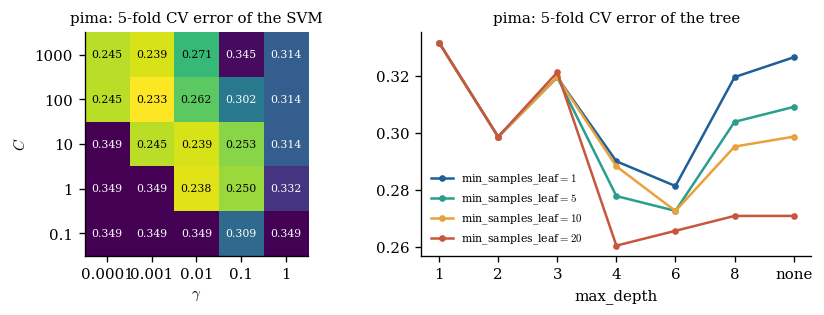

In [14]:
show_figure("tp1_grid")

In [15]:
show_table("p3_selected")

| model | selected hyperparameters | CV error | test error |
|:---:|:---:|:---:|:---:|
| SVM | $C=100$, $\gamma=0.001$ | 0.233 | 0.229 |
| tree | depth 4, leaf 20 | 0.260 | 0.224 |

The heat map shows a valley of good pairs: a small $\gamma$ (a wide, smooth kernel) needs a large $C$ (little regularization), and conversely; a too large $\gamma$ overfits as soon as $C\geq1$, and a too small $C$ with a small $\gamma$ predicts the majority class ($0.349$, the proportion of diabetic patients). For the tree, depth $4$--$6$ is best and a minimal number of examples per leaf regularizes the deep trees. Several cells are within $0.01$ of the best one: the exact choice inside this region hardly matters.

**2.** Over $30$ random partitions of the learning set:

In [16]:
show_table("p3_holdout_cv")

| procedure | distinct pairs selected | selected validation error | test error of the selected model |
|:---:|:---:|:---:|:---:|
| hold-out (75/25) | 8 | 0.223 (0.024) | 0.224 (0.007) |
| 5-fold CV | 6 | 0.230 (0.005) | 0.223 (0.008) |

With a single hold-out split, the validation error of the selected pair depends a lot on the split (standard deviation $0.024$, i.e. $3$ to $4$ errors out of $144$ validation examples), and the selected pair changes often. Cross-validation averages $5$ estimates that cover the whole learning set: its score is five times more stable, and the choice slightly more stable. Here the final test errors are similar, because the region of good pairs is flat; on smaller or harder problems, a hold-out choice can be clearly worse. Cross-validation costs $5$ times more computations, which is a good price when data are scarce.

## Part 4 – The complete protocol, and the optimism of the best score

1.  Write a function that, given a dataset and a seed, (i) splits it into a learning set ($75\%$) and a test set, (ii) selects the hyperparameters of the SVM pipeline and of the tree by $5$-fold cross-validation on the learning set (`GridSearchCV`), (iii) retrains them on the whole learning set and (iv) computes their test errors.\
    Run it on `wdbc`, `pima` and `australian` for $10$ seeds, and compare the best cross-validation error with the test error.

2.  To understand the difference, replace the labels of `pima` by random labels (independent of the features) and run the same protocol for the SVM.\
    What is the true risk of any classifier?\
    What do you observe?

In [17]:
def part4():
    print("Part 4")
    rows = []
    for name in ["wdbc", "pima", "australian"]:
        X, y = load(name); R = []
        for seed in range(10):
            Xtv, Xte, ytv, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
            cv = StratifiedKFold(5, shuffle=True, random_state=seed)
            gs = GridSearchCV(svm_pipe(), {"svc__C": CS, "svc__gamma": GAMMAS}, cv=cv).fit(Xtv, ytv)
            gt = GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": DEPTHS, "min_samples_leaf": LEAVES}, cv=cv).fit(Xtv, ytv)
            R.append((1 - gs.best_score_, err(gs, Xte, yte), 1 - gt.best_score_, err(gt, Xte, yte)))
        M = np.mean(R, 0)
        rows.append(f"{name} & {M[0]:.3f} & {M[1]:.3f} & {M[2]:.3f} & {M[3]:.3f}")
    keep_table("p4_protocol", rows)
    # optimism of the best CV score: random labels on pima features
    X, _ = load("pima"); rng = np.random.RandomState(0); best, test = [], []
    for rep in range(10):
        yr = rng.choice([-1, 1], len(X))
        Xtv, Xte, ytv, yte = train_test_split(X, yr, test_size=0.25, random_state=rep)
        gs = GridSearchCV(svm_pipe(), {"svc__C": CS, "svc__gamma": GAMMAS}, cv=StratifiedKFold(5, shuffle=True, random_state=rep)).fit(Xtv, ytv)
        best.append(1 - gs.best_score_); test.append(err(gs, Xte, yte))
    keep_table("p4_random", [f"{len(CS) * len(GAMMAS)} & {np.mean(best):.3f} ({np.std(best):.3f}) & {np.mean(test):.3f} ({np.std(test):.3f})"])
    print("   random labels: best CV", np.mean(best), "test", np.mean(test))

In [18]:
part4()

Part 4


   random labels: best CV 0.4725667166416792 test 0.4921875


### Solution

**1.** Averages over $10$ seeds:

In [19]:
show_table("p4_protocol")

| data | SVM ($25$ pairs) – best CV error | SVM ($25$ pairs) – test error | tree ($28$ pairs) – best CV error | tree ($28$ pairs) – test error |
|:---:|:---:|:---:|:---:|:---:|
| wdbc | 0.019 | 0.030 | 0.057 | 0.070 |
| pima | 0.220 | 0.240 | 0.243 | 0.256 |
| australian | 0.135 | 0.146 | 0.138 | 0.154 |

The best cross-validation error is systematically smaller than the test error of the selected model (by $0.01$ to $0.02$). The SVM is better than the tree on `wdbc` and `pima`, and slightly better on `australian`.

**2.** With random labels, every classifier has a true risk of exactly $\frac12$:

In [20]:
show_table("p4_random")

| number of pairs | best CV error | test error |
|:---:|:---:|:---:|
| 25 | 0.473 (0.017) | 0.492 (0.049) |

The test error is close to $\frac12$, as it should be, but the best of the $25$ cross-validation errors is $0.47$: the minimum of $25$ noisy estimates of $\frac12$ is below $\frac12$. The cross-validation score of the *selected* model is an optimistic estimate of its risk, for the same reason as the training error in Part 1, only milder: it has been used to choose. This is why the final evaluation must be done on a test set that played no role in the choice, and why, in Part 6, a guarantee computed on a set used for selection must pay for the selection.

## Part 5 – Opening: what if we combine many trees? (Section 10.2)

1.  On the synthetic problem ($m=300$) and on `pima` ($70\%/30\%$), learn $B=100$ fully grown trees, each one on a *bootstrap sample* of the training set ($m$ indices drawn with replacement), and predict by the majority vote $\operatorname{sign}\big(\sum_{b}h_b(x)\big)$.\
    Compare the test error of the vote with that of one fully grown tree learned on the whole training set, and with the mean test error of the $100$ trees.

2.  Why can a vote be much better than its voters?

In [21]:
def part5():
    print("Part 5")
    rows = []
    for name in ["toy", "pima"]:
        if name == "toy":
            rng = np.random.RandomState(1); Xtr, ytr = toy_data(300, rng); Xte, yte = toy_data(20000, rng)
        else:
            X, y = load(name); Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
        rng = np.random.RandomState(0); B = 100; V = []
        single = err(DecisionTreeClassifier(random_state=0).fit(Xtr, ytr), Xte, yte)
        for b in range(B):
            idx = rng.randint(0, len(ytr), len(ytr))
            V.append(DecisionTreeClassifier(random_state=b).fit(Xtr[idx], ytr[idx]).predict(Xte))
        V = np.array(V); vote = np.mean(np.where(V.sum(0) >= 0, 1, -1) != yte); mean_tree = np.mean(V != yte[None, :])
        rows.append(f"{name} & {single:.3f} & {mean_tree:.3f} & {vote:.3f}")
    keep_table("p5_vote", rows)

In [22]:
part5()

Part 5


### Solution

**1.**

In [23]:
show_table("p5_vote")

| data | one full tree | mean error of the $100$ trees | vote of the $100$ trees |
|:---:|:---:|:---:|:---:|
| toy | 0.182 | 0.194 | 0.137 |
| pima | 0.299 | 0.296 | 0.238 |

The vote reduces the error by $4$ to $6$ points with respect to one tree, and is much better than the average tree.

**2.** A fully grown tree overfits and is very unstable: two trees learned on two bootstrap samples make *different* errors. On a given point, the vote is wrong only if a majority of the trees are wrong; if their errors were independent and each tree erred with probability $r<\frac12$, the probability that the majority errs would tend to $0$ with $B$ (Condorcet's jury theorem). The errors are not independent in practice, but averaging still removes a large part of the variance. This method is called *bagging* (bootstrap aggregating) and is the subject of TP 2; TP 3 builds the voters sequentially (boosting). TP 4 and 5 will show how to *certify* such votes with PAC-Bayesian bounds, in which the mean error of the voters (the *Gibbs risk*) plays a central role.

## Part 6 – Opening: a first guarantee on the true risk (Sections 1.4 and 6.2)

Let $h$ be a classifier *fixed before* drawing a test sample $T$ of $n$ i.i.d. examples. Hoeffding's inequality gives, with probability at least $1-\delta$ over $T$, $$R_{\mathcal{D}}(h)\leq\widehat R_T(h)+\sqrt{\frac{\ln(1/\delta)}{2n}} ,$$ and a tighter version, based on the Chernoff bound, is $R_{\mathcal{D}}(h)\leq\overline{\operatorname{kl}}^{-1}\big(\widehat R_T(h),\frac{\ln(1/\delta)}{n}\big)$, where $\overline{\operatorname{kl}}^{-1}(q,\varepsilon)=\sup\{p\in[q,1]:\operatorname{kl}(q\|p)\leq\varepsilon\}$ and $\operatorname{kl}(q\|p)=q\ln\frac qp+(1-q)\ln\frac{1-q}{1-p}$ (`kl_inv_upper` in `common/tptools.py`). We take $\delta=0.05$.

1.  Prove the Hoeffding bound from $\mathbb{P}\big(R_{\mathcal{D}}(h)-\widehat R_T(h)\geq\varepsilon\big)\leq e^{-2n\varepsilon^2}$.

2.  Compute both bounds for the SVM selected in Part 4 (seed $0$) on the three datasets.\
    Interpret them.\
    How many test examples would be needed for a Hoeffding term of $0.01$?

3.  On the synthetic problem, fix the SVM with $\gamma=3$ learned on $200$ examples, draw $1000$ test sets of size $n\in\{50,200,1000\}$ and check that both bounds hold in at least $95\%$ of the cases.

4.  **Selection.** Why can the bound not be applied to the best cross-validation score of Part 4?\
    Simulate $K$ useless classifiers (true risk $\frac12$) whose errors on a common validation set of $n=100$ examples are independent $\mathcal B(n,\frac12)/n$, select the best one, and compute how often the Hoeffding bound holds for it, for $K\in\{1,25,1000\}$.\
    Show that replacing $\delta$ by $\delta/K$ (union bound) repairs it.

In [24]:
def part6():
    print("Part 6")
    rows = []
    for name in ["wdbc", "pima", "australian"]:
        X, y = load(name)
        Xtv, Xte, ytv, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
        gs = GridSearchCV(svm_pipe(), {"svc__C": CS, "svc__gamma": GAMMAS}, cv=StratifiedKFold(5, shuffle=True, random_state=0)).fit(Xtv, ytv)
        n = len(yte); e = err(gs, Xte, yte)
        rows.append(f"{name} & {n} & {e:.3f} & {e + hoeffding_width(n, DELTA):.3f} & {kl_inv_upper(e, np.log(1 / DELTA) / n):.3f}")
    keep_table("p6_bounds", rows)
    # coverage of the bound on the toy problem: fixed model, many test sets
    rng = np.random.RandomState(2); Xtr, ytr = toy_data(200, rng); Xbig, ybig = toy_data(50000, rng)
    s = SVC(C=10, gamma=3).fit(Xtr, ytr); R = err(s, Xbig, ybig); rows = []
    for n in [50, 200, 1000]:
        e = np.array([err(s, *toy_data(n, rng)) for _ in range(1000)])
        rows.append(f"{n} & {R:.3f} & {np.mean(e + hoeffding_width(n, DELTA)):.3f} & {np.mean(R <= e + hoeffding_width(n, DELTA)):.3f} & "
                    f"{np.mean(kl_inv_upper(e, np.log(1 / DELTA) / n)):.3f} & {np.mean(R <= kl_inv_upper(e, np.log(1 / DELTA) / n)):.3f}")
    keep_table("p6_coverage", rows)
    # selection: K useless classifiers on a validation set of n = 100 examples
    rng = np.random.RandomState(3); n = 100; rows = []
    for K in [1, 25, 1000]:
        best = rng.binomial(n, 0.5, size=(2000, K)).min(1) / n
        rows.append(f"{K} & {best.mean():.3f} & {np.mean(0.5 <= best + hoeffding_width(n, DELTA)):.3f} & "
                    f"{np.mean(0.5 <= best + hoeffding_width(n, DELTA / K)):.3f}")
    keep_table("p6_selection", rows)

In [25]:
part6()

Part 6


### Solution

**1.** With $\varepsilon=\sqrt{\ln(1/\delta)/(2n)}$, $e^{-2n\varepsilon^2}=\delta$: the event $\{R_{\mathcal{D}}(h)>\widehat R_T(h)+\varepsilon\}$ has probability at most $\delta$, and its complement, the bound, has probability at least $1-\delta$. The proof requires the $\mathbb{1}\left[h(x_i)\neq y_i\right]$ to be i.i.d., hence $h$ independent of $T$.

**2.**

In [26]:
show_table("p6_bounds")

| data | $n$ | test error | Hoeffding bound | kl bound |
|:---:|:---:|:---:|:---:|:---:|
| wdbc | 143 | 0.028 | 0.130 | 0.075 |
| pima | 192 | 0.229 | 0.317 | 0.309 |
| australian | 173 | 0.145 | 0.238 | 0.218 |

With $95\%$ confidence, the SVM has a true error below $7.5\%$ on `wdbc`, $31\%$ on `pima` and $22\%$ on `australian`. These guarantees are valid because the test set was used only once. They are loose because the test sets are small: the Hoeffding term is about $0.09$--$0.10$ for $n\approx150$--$190$. The kl bound is much tighter when the error is small (`wdbc`). A Hoeffding term of $0.01$ requires $n\geq\ln(20)/(2\times10^{-4})\approx15\,000$ test examples.

**3.** Mean bounds and proportion of test sets for which the bound holds:

In [27]:
show_table("p6_coverage")

| $n$ | $R_{\mathcal{D}}(h)$ | mean Hoeffding | coverage | mean kl bound | coverage |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 50 | 0.126 | 0.296 | 1.000 | 0.261 | 0.991 |
| 200 | 0.126 | 0.209 | 1.000 | 0.186 | 0.993 |
| 1000 | 0.126 | 0.161 | 1.000 | 0.149 | 0.969 |

Both bounds hold in at least $95\%$ of the cases, as guaranteed; they are conservative (Hoeffding's inequality is valid for any distribution on $[0,1]$, not only Bernoulli ones).

**4.** The best cross-validation score belongs to a model chosen *because* its score is small: the model depends on the data used to evaluate it. In the simulation:

In [28]:
show_table("p6_selection")

| $K$ | selected error | coverage with $\delta$ | coverage with $\delta/K$ |
|:---:|:---:|:---:|:---:|
| 1 | 0.500 | 0.995 | 0.995 |
| 25 | 0.402 | 0.861 | 0.995 |
| 1000 | 0.339 | 0.004 | 0.997 |

With $1000$ useless classifiers, the best one seems to have an error of $34\%$ and the naive bound fails almost always. The union bound gives $\mathbb{P}\big(\exists k:R_{\mathcal{D}}(h_k)>\widehat R(h_k)+\varepsilon\big)\leq\sum_k\mathbb{P}\big(R_{\mathcal{D}}(h_k)>\widehat R(h_k)+\varepsilon\big)\leq Ke^{-2n\varepsilon^2}$, so that with $\varepsilon=\sqrt{\ln(K/\delta)/(2n)}$ the bound holds for all the classifiers at once, hence for the selected one. The price is only $\ln K$: this is the first generalization bound of the course (the one-sided version of Theorem 6.1). TP 4 and 5 go further: they replace the uniform price $\ln K$ by a *prior* over the classifiers, and certify not one classifier but a distribution over classifiers, hence a vote (PAC-Bayes).

## Part 7 – Going further $(\star)$

1.  Prove that the Bayes classifier $h^\star(x)=\operatorname{sign}(2\eta(x)-1)$ (either label when $\eta(x)=\frac12$), with $\eta(x)=\mathbb{P}(Y=1\mid X=x)$, minimizes the true risk, and that $R^\star=\mathbb{E}[\min(\eta(X),1-\eta(X))]$.

2.  **Data leakage.** Draw $m=100$ examples with $d=2000$ Gaussian features and labels drawn uniformly in $\{-1,+1\}$, independently of the features.\
    (a) Select the $20$ features most correlated with the label on the whole dataset, then estimate the accuracy of a logistic regression on these features by $5$-fold cross-validation.\
    (b) Do the same, but perform the selection inside each fold, on the training part only.\
    Repeat $10$ times and compare with the true accuracy.

In [29]:
def part7():
    print("Part 7")
    rng = np.random.RandomState(0); m, d, k_sel = 100, 2000, 20; R = []
    def select(Xa, ya):
        c = np.abs((Xa - Xa.mean(0)).T @ (ya - ya.mean())) / (Xa.std(0) + 1e-12)
        return np.argsort(-c)[:k_sel]
    for rep in range(10):
        Xr = rng.randn(m, d); yr = rng.choice([-1, 1], m)
        feats = select(Xr, yr); wrong, right = [], []
        for a, b in StratifiedKFold(5, shuffle=True, random_state=rep).split(Xr, yr):
            clf = LogisticRegression(max_iter=2000).fit(Xr[a][:, feats], yr[a]); wrong.append(np.mean(clf.predict(Xr[b][:, feats]) == yr[b]))
            f2 = select(Xr[a], yr[a]); clf = LogisticRegression(max_iter=2000).fit(Xr[a][:, f2], yr[a]); right.append(np.mean(clf.predict(Xr[b][:, f2]) == yr[b]))
        R.append((np.mean(wrong), np.mean(right)))
    R = np.array(R)
    keep_table("p7_leakage", [f"{R[:, 0].mean():.3f} ({R[:, 0].std():.3f}) & {R[:, 1].mean():.3f} ({R[:, 1].std():.3f})"])
    print("   leakage", R.mean(0))

In [30]:
part7()

Part 7


   leakage [0.852 0.529]


### Solution

**1.** For any classifier $h$, conditionally on $X=x$, $\mathbb{P}(h(X)\neq Y\mid X=x)=\eta(x)\mathbb{1}\left[h(x)=-1\right]+(1-\eta(x))\mathbb{1}\left[h(x)=1\right]\geq\min(\eta(x),1-\eta(x))$, with equality when $h(x)$ is the most probable label, i.e. $h(x)=h^\star(x)$. Taking the expectation over $X$ gives $R_{\mathcal{D}}(h)\geq\mathbb{E}[\min(\eta(X),1-\eta(X))]=R_{\mathcal{D}}(h^\star)$. In Part 1, $\eta(x)\in\{0.1,0.9\}$, hence $R^\star=0.1$.

**2.** Mean (standard deviation) of the cross-validated accuracy over $10$ repetitions:

In [31]:
show_table("p7_leakage")

| (a) selection on all the data | (b) selection inside each fold |
|:---:|:---:|
| 0.852 (0.045) | 0.529 (0.077) |

Every classifier has accuracy exactly $\frac12$. Procedure (a) reports $85\%$: with $2000$ features and $100$ examples, some features are correlated with the labels by chance, and the selection has seen the labels of the validation folds. Procedure (b), where every step that looks at the labels is inside the loop, gives $0.53\pm0.08$. Rule: the *whole* pipeline, preprocessing and selection included, must be fitted on the training part only.